**Avvio locale e Colab:** preparare la cartella completa seguendo il [README del laboratorio](README.md). Conservare gli identificativi delle celle e salvare gli output nel proprio runtime.

# Images as NumPy Arrays — Computer Vision 2026

**Lezione 2 · Image Formation Studio**  
Laurea Magistrale in Ingegneria Informatica · secondo anno

> Un'immagine digitale non è soltanto una figura: è un array con forma, tipo, intervallo numerico e significato fisico.

Percorso ispirato al [Python/NumPy Tutorial di Stanford CS231n](https://cs231n.github.io/python-numpy-tutorial/) e al relativo [notebook Colab](https://colab.research.google.com/github/cs231n/cs231n.github.io/blob/master/python-colab.ipynb), adattato alla formazione dell'immagine.

Nei materiali del corso si usa il **punto decimale** (0.5) e la **virgola seguita da uno spazio** fra componenti di vettori e argomenti, per esempio (1.2, 1, −0.3). I conteggi interi non usano separatori delle migliaia.

## Come usare il notebook

**Percorso essenziale nello studio**

1. eseguire le sezioni 1–5;
2. confrontare i risultati con un collega;
3. annotare una previsione prima di modificare ogni parametro.

**Approfondimento sul campionamento**

Eseguire la sezione 6 per confrontare sottocampionamento diretto e prefiltro. Le sezioni marcate *Extra* possono essere svolte prima del corso o in autonomia.

## 1. Setup e immagine fotografica

Il notebook usa il ritratto di Grace Hopper distribuito con Matplotlib e, nella sezione 2, una fotografia sottomarina NOAA inclusa nel file: non occorre scaricare dati. In Colab si può attivare `USE_UPLOAD=True` e caricare uno scatto proprio; in quel caso il primo confronto usa un crop centrale della foto caricata e l'ordine dei canali va verificato sui nuovi dati.

In [1]:
import io
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cbook import get_sample_data
from PIL import Image, ImageFilter

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'image.cmap': 'gray'})
print('NumPy:', np.__version__)

NumPy: 2.3.5


In [2]:
USE_UPLOAD = False  # Impostare True in Colab per usare una propria fotografia

if USE_UPLOAD:
    try:
        from google.colab import files
        uploaded = files.upload()
        name, payload = next(iter(uploaded.items()))
        pil_image = Image.open(io.BytesIO(payload)).convert('RGB')
        source_name = name
    except (ImportError, StopIteration):
        raise RuntimeError('Il caricamento interattivo è disponibile in Google Colab.')
else:
    sample_path = get_sample_data('grace_hopper.jpg', asfileobj=False)
    pil_image = Image.open(sample_path).convert('RGB')
    source_name = 'grace_hopper.jpg — Matplotlib sample data'

# Copia scrivibile: eventuali esperimenti sugli slice non dipendono dal buffer PIL.
img = np.array(pil_image, copy=True)
print('Sorgente:', source_name)
print('shape:', img.shape, 'dtype:', img.dtype, 'min/max:', (img.min(), img.max()))

Sorgente: grace_hopper.jpg — Matplotlib sample data
shape: (600, 512, 3) dtype: uint8 min/max: (np.uint8(0), np.uint8(255))


### Previsione 1

Prima di eseguire la cella successiva: quale asse rappresenta le righe, quale le colonne e quale i canali? Perché un pixel RGB non è un singolo numero?

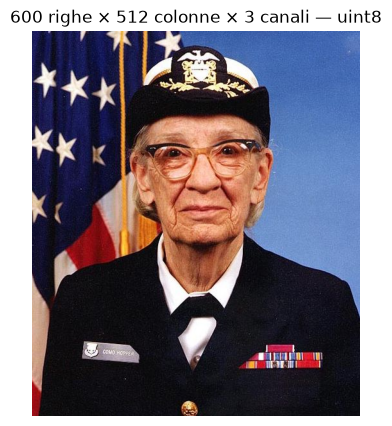

In [3]:
H, W, C = img.shape
assert C == 3 and img.dtype == np.uint8

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(img)
ax.set_title(f'{H} righe × {W} colonne × {C} canali — {img.dtype}')
ax.axis('off')
plt.show()

## 2. Indicizzazione: crop e canali

La sintassi è `img[righe, colonne, canali]`. Lo slicing seleziona una regione senza scrivere cicli espliciti sui pixel; l'estremo finale di ogni intervallo è escluso.

### 2A. Un volto: RGB, R, G, B sulla stessa riga

Ritagliamo il volto di Grace Hopper. Ogni canale viene mostrato **in grigio, sulla stessa scala 0–255**: più chiaro significa codice digitale maggiore. Anticipiamo una misura della sezione 5: la media di ciascun canale sul ritaglio, `crop.mean(axis=(0, 1))`.

**Previsione 2A.** Il volto apparirà più chiaro in R o in B? Perché, per confrontarli, dobbiamo fissare `vmin=0` e `vmax=255` per entrambi?

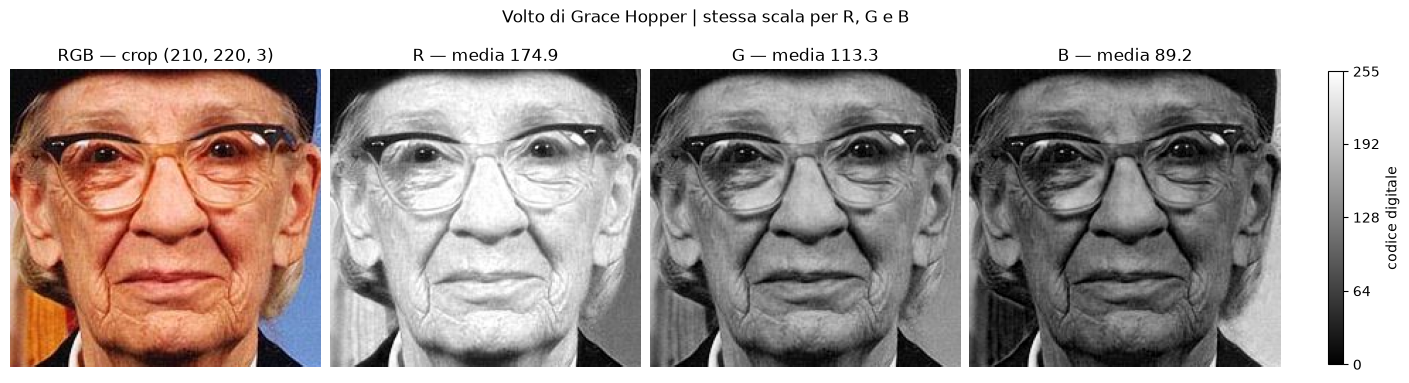

Medie RGB del crop, scala 0–255: [174.9 113.3  89.2]


In [4]:
if not USE_UPLOAD:
    # Coordinate del volto nel campione Grace Hopper (600 righe, 512 colonne).
    r0, r1 = 130, 340
    c0, c1 = 155, 375
    crop_label = 'Volto di Grace Hopper'
else:
    # Per una foto propria, adattare questi estremi alla regione di interesse.
    r0, r1 = H // 4, 3 * H // 4
    c0, c1 = W // 4, 3 * W // 4
    crop_label = 'Crop della foto caricata'

crop = img[r0:r1, c0:c1]
crop_means = crop.mean(axis=(0, 1))

fig, axes = plt.subplots(1, 4, figsize=(14, 4), layout='constrained')
axes[0].imshow(crop)
axes[0].set_title(f'RGB — crop {crop.shape}')
for channel, label, ax in zip(range(3), 'RGB', axes[1:]):
    channel_view = ax.imshow(crop[:, :, channel], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{label} — media {crop_means[channel]:.1f}')
for ax in axes:
    ax.axis('off')
fig.colorbar(channel_view, ax=axes[1:].tolist(), shrink=0.8,
             ticks=[0, 64, 128, 192, 255], label='codice digitale')
fig.suptitle(crop_label + ' | stessa scala per R, G e B')
plt.show()
print('Medie RGB del crop, scala 0–255:', crop_means.round(1))

### 2B. Sott'acqua: che cosa cambia lungo il percorso della luce?

Confrontiamo ora una **fotografia reale di un fondale con mitili**, presso il vulcano Giggenbach, vicino alla Nuova Zelanda. La scheda NOAA indica circa **100 m di profondità e sola luce solare**. La foto è inclusa nel notebook: eseguire anche la cella dati ripiegata, senza modificarla.

**Previsione 2B.** L'ordine delle medie RGB sarà lo stesso del volto? Quale canale appare più chiaro in questa fotografia? Quel canale deve prevalere in *ogni* foto sottomarina?

Fonte: [foto e descrizione originali NOAA](https://archive.oceanexplorer.noaa.gov/explorations/05fire/logs/april18/media/ambient_mussels.html); [scheda Light and Color in the Deep Sea](https://oceanexplorer.noaa.gov/edu/materials/light-and-color-fact-sheet.pdf). Crediti: New Zealand-American Submarine Ring of Fire 2005 Exploration, NOAA Vents Program. Il JPEG è usato senza correzioni del colore.

In [5]:
#@title Fotografia NOAA inclusa — eseguire senza modificare i dati
# Cella dati ripiegata: contiene il JPEG originale, senza correzioni cromatiche.
# Fonte e crediti sono indicati nel testo precedente.
import base64

underwater_jpeg_b64 = '...'

underwater = np.array(Image.open(io.BytesIO(base64.b64decode(underwater_jpeg_b64))).convert('RGB'), copy=True)
print('Fotografia NOAA caricata:', underwater.shape, underwater.dtype)

Fotografia NOAA caricata: (450, 600, 3) uint8


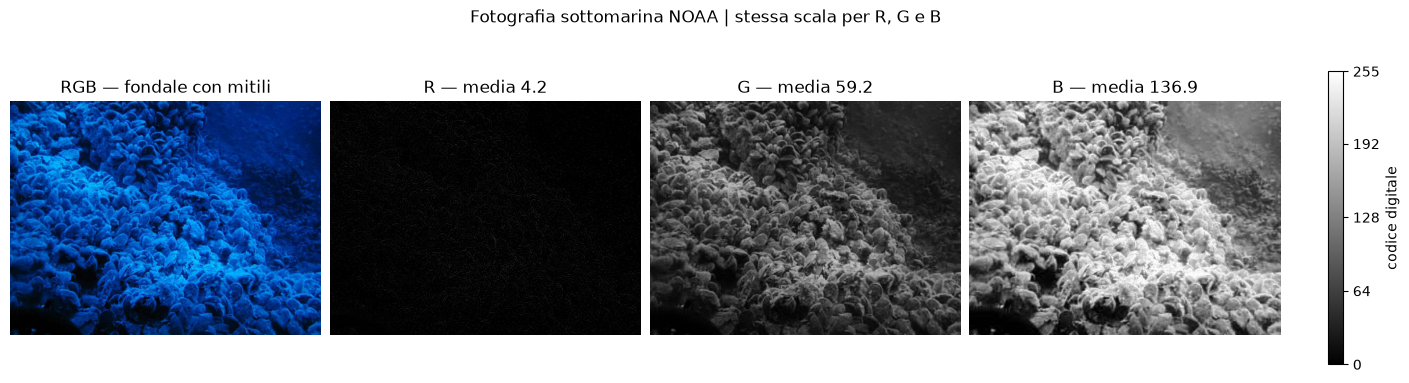

Medie RGB della foto sottomarina, scala 0–255: [  4.2  59.2 136.9]


In [6]:
# Usiamo l'intera foto NOAA: le tre medie si riferiscono agli stessi pixel.
underwater_means = underwater.mean(axis=(0, 1))

fig, axes = plt.subplots(1, 4, figsize=(14, 4), layout='constrained')
axes[0].imshow(underwater)
axes[0].set_title('RGB — fondale con mitili')
for channel, label, ax in zip(range(3), 'RGB', axes[1:]):
    channel_view = ax.imshow(underwater[:, :, channel], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{label} — media {underwater_means[channel]:.1f}')
for ax in axes:
    ax.axis('off')
fig.colorbar(channel_view, ax=axes[1:].tolist(), shrink=0.8,
             ticks=[0, 64, 128, 192, 255], label='codice digitale')
fig.suptitle('Fotografia sottomarina NOAA | stessa scala per R, G e B')
plt.show()
print('Medie RGB della foto sottomarina, scala 0–255:', underwater_means.round(1))

### 2C. Dal confronto dei canali alla formazione dell'immagine

Il valore RGB dipende dalla luce disponibile, dalla superficie, dal **mezzo attraversato** e dalla camera. Nell'acqua il rosso tende ad attenuarsi maggiormente; in acque limpide può prevalere il blu, mentre in altre condizioni può prevalere il verde. Non significa che l'acqua amplifichi quei canali: cambia la luce che arriva alla camera e il suo equilibrio spettrale.

Stiamo confrontando **codici di due JPEG di scene diverse**, non una misura controllata della stessa scena in aria e in acqua. Riflettanze, distanza, illuminazione artificiale, bilanciamento del bianco e altre elaborazioni possono cambiare l'ordine dei canali. Le medie non misurano direttamente energia ottica o coefficienti di assorbimento, e un canale non rappresenta una singola lunghezza d'onda.

**Discussione 2C.** Per isolare l'effetto del mezzo, che cosa bisognerebbe mantenere fisso? Aumentare poi il guadagno del rosso recupera anche l'informazione che non è stata registrata?

Riferimenti: [NOAA — Why is the ocean blue?](https://oceanservice.noaa.gov/facts/oceanblue.html), [NOAA — Light and Color in the Deep Sea](https://oceanexplorer.noaa.gov/edu/materials/light-and-color-fact-sheet.pdf).

### Attenzione: view e copy

Molti slice NumPy sono **viste** degli stessi dati. Modificare la vista può quindi modificare l'immagine originale. Quando si vuole un esperimento indipendente, usare `.copy()`.

In [7]:
demo = np.arange(9).reshape(3, 3)
view = demo[:2, :2]
safe_copy = demo[:2, :2].copy()
view[0, 0] = 99
safe_copy[1, 1] = -1
print('Array originale dopo la modifica della view:\n', demo)
print('Copia indipendente:\n', safe_copy)

Array originale dopo la modifica della view:
 [[99  1  2]
 [ 3  4  5]
 [ 6  7  8]]
Copia indipendente:
 [[ 0  1]
 [ 3 -1]]


## 3. `uint8`, float e clipping

Una fotografia comune usa interi tra 0 e 255. Per calcolare conviene convertire in float e normalizzare in $[0, 1]$. Sommare o moltiplicare direttamente valori `uint8` può produrre overflow; una pipeline corretta dichiara sempre tipo e intervallo.

Il JPEG è già codificato e processato: moltiplicarne i valori è un guadagno numerico, non una simulazione radiometrica dell’esposizione. Il clipping riportato sotto conta le componenti RGB, non i pixel. Un pixel può avere uno, due o tre canali tagliati.

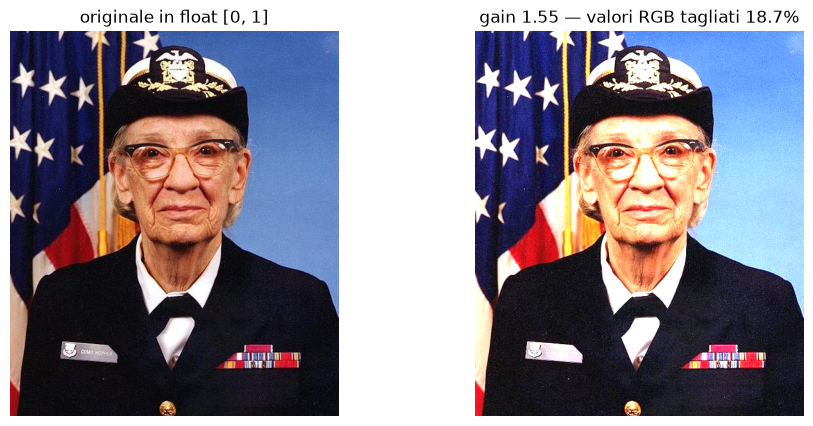

In [8]:
img_f = img.astype(np.float32) / 255.0
exposure_gain = 1.55
bright = np.clip(img_f * exposure_gain, 0.0, 1.0)
clipped_fraction = np.mean(img_f * exposure_gain > 1.0)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(img_f)
axes[0].set_title('originale in float [0, 1]')
axes[1].imshow(bright)
axes[1].set_title(f'gain {exposure_gain:.2f} — valori RGB tagliati {100*clipped_fraction:.1f}%')
for ax in axes:
    ax.axis('off')
plt.show()

### Previsione 2

Aumentare il guadagno numerico rende visibili nuovi fotoni? Che differenza c'è tra una zona più chiara e una zona saturata?

## 4. Broadcasting: un guadagno per canale

Un vettore di forma `(3,)` viene applicato a tutte le righe e colonne. Questa è la struttura numerica elementare di un bilanciamento del bianco a guadagni diagonali.

I guadagni dell’esempio sono scelti a mano per osservare il broadcasting; non sono una stima dell’illuminante e non certificano una correzione cromatica. La moltiplicazione sul JPEG serve a capire la struttura numerica.

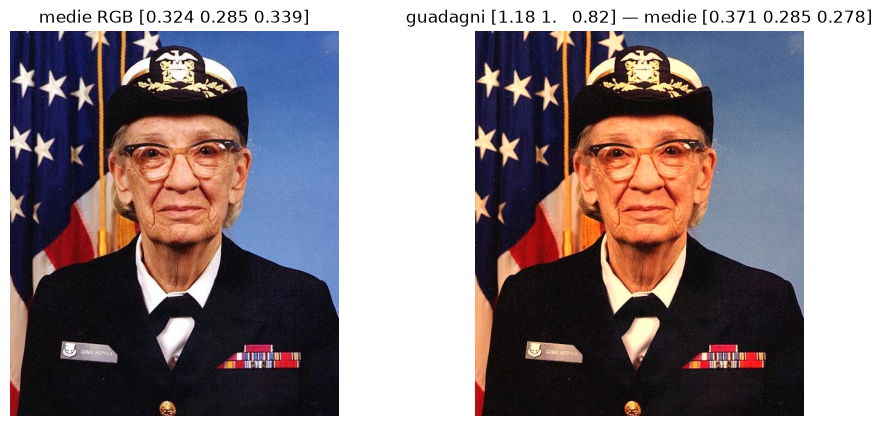

In [9]:
wb_gains = np.array([1.18, 1.00, 0.82], dtype=np.float32)
balanced = np.clip(img_f * wb_gains, 0.0, 1.0)  # broadcasting su H × W × 3
means_before = img_f.mean(axis=(0, 1))
means_after = balanced.mean(axis=(0, 1))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(img_f)
axes[0].set_title(f'medie RGB {means_before.round(3)}')
axes[1].imshow(balanced)
axes[1].set_title(f'guadagni {wb_gains} — medie {means_after.round(3)}')
for ax in axes:
    ax.axis('off')
plt.show()

## 5. Riduzioni: dall'immagine a una misura

`mean`, `min`, `max` e gli istogrammi comprimono molti pixel in poche quantità. Una misura globale è utile, ma può nascondere saturazioni locali e variazioni spaziali.

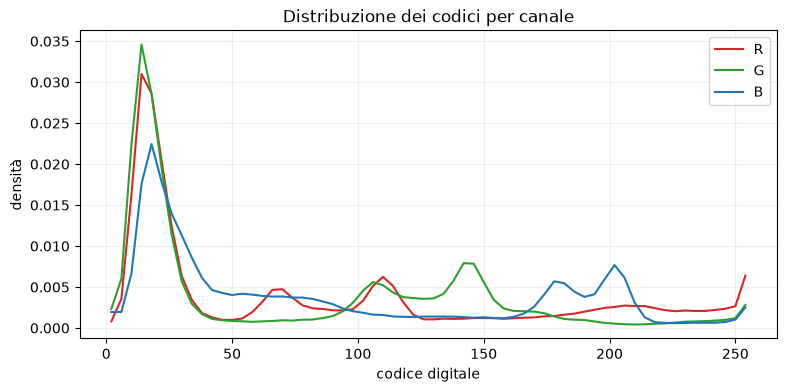

In [10]:
channel_names = ['R', 'G', 'B']
channel_colors = ['tab:red', 'tab:green', 'tab:blue']
fig, ax = plt.subplots(figsize=(9, 4))
for k, (name, color) in enumerate(zip(channel_names, channel_colors)):
    hist, edges = np.histogram(img[:, :, k], bins=64, range=(0, 256), density=True)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.plot(centers, hist, color=color, label=name)
ax.set(xlabel='codice digitale', ylabel='densità', title='Distribuzione dei codici per canale')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 6. Sampling e aliasing

Confrontiamo due operazioni sulla **stessa griglia** e con lo **stesso numero di campioni**:

- `img[::factor, ::factor]`: selezione diretta;
- prefiltro gaussiano, poi lo stesso slicing.

Con passo iniziale di un pixel, dopo una riduzione di fattore `k` la frequenza di Nyquist è `1/(2*k)` cicli per pixel originale. Il pattern circolare qui ha frequenza locale crescente verso i bordi; il valore massimo orizzontale è circa 0.269 cicli/pixel. La scala del prefiltro cresce con il fattore. Il filtro gaussiano attenua gradualmente le alte frequenze: non è un taglio ideale e non garantisce l’eliminazione completa dell’aliasing.

**Previsione:** con `factor=4`, quali regioni del pattern diventano più problematiche? Dove deve agire il filtro?

Gli spettri mostrano l’ampiezza della FFT 2D dopo sottrazione della media, in dB con lo stesso riferimento e la stessa scala. Gli assi sono in cicli per pixel originale. Non confondere la perdita di contrasto voluta dal prefiltro con una nuova misura della scena.

factor=4; sigma=2.40 pixel originali; Nyquist=0.1250 cicli/pixel originale
forme foto: (150, 128, 3) (150, 128, 3)


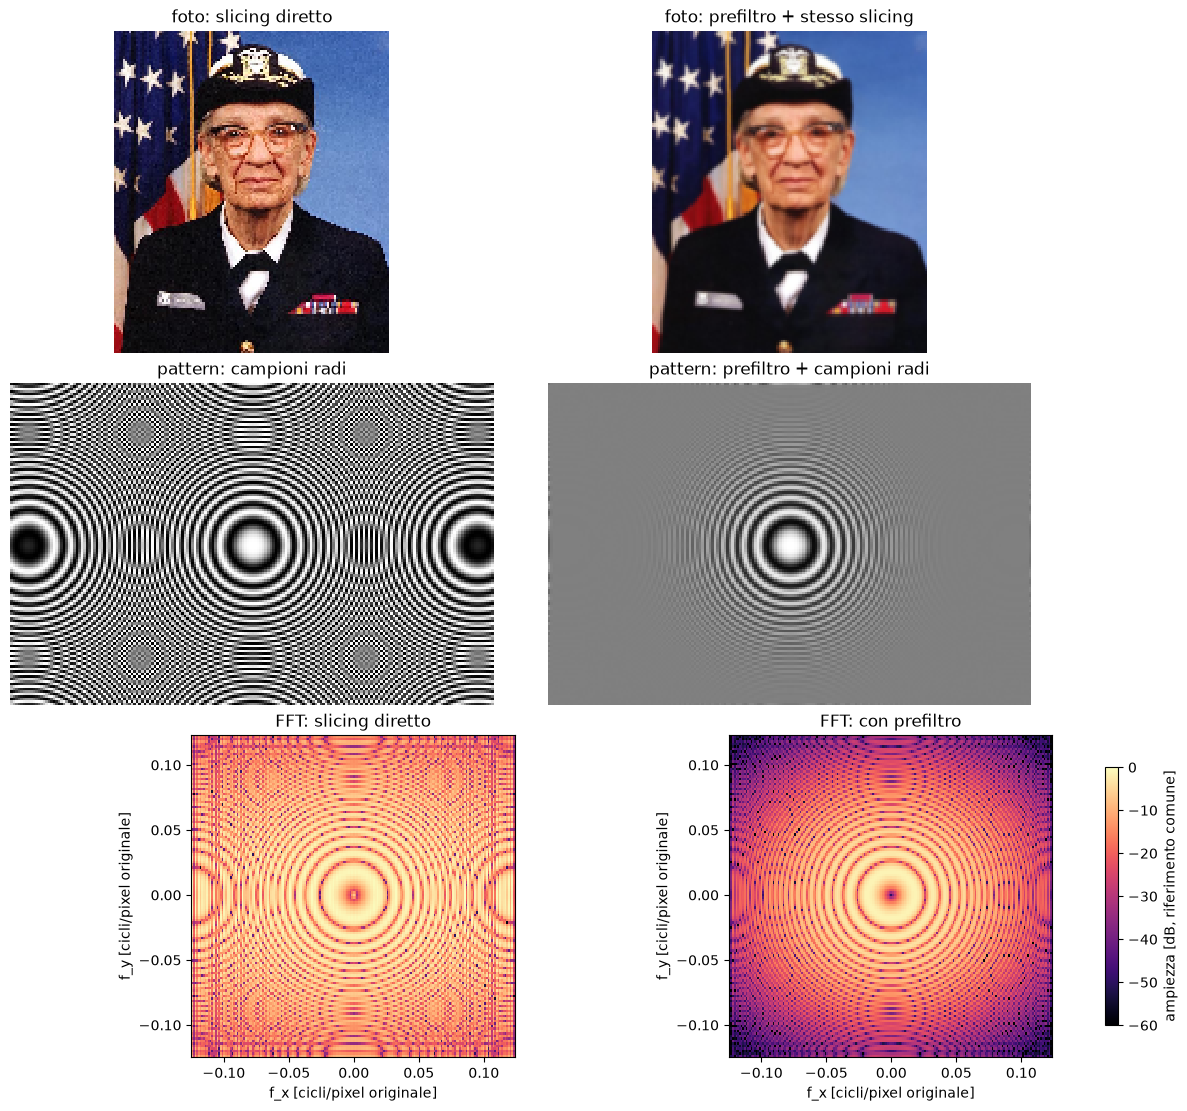

In [11]:
factor = 4
assert isinstance(factor, int) and factor >= 2
sigma = 0.6 * factor  # pixel ORIGINALI; attenuazione graduale, non taglio ideale
stride = img[::factor, ::factor]
photo_filtered = np.asarray(pil_image.filter(ImageFilter.GaussianBlur(radius=sigma)))
prefiltered = photo_filtered[::factor, ::factor]
assert stride.shape == prefiltered.shape  # vale anche per dimensioni non divisibili

# Zone plate: variazione controllata della frequenza spaziale.
yy, xx = np.mgrid[:512, :768]
phase_coefficient = 0.0022
zone_plate = 0.5 + 0.5 * np.cos(phase_coefficient * ((xx - 384)**2 + (yy - 256)**2))
zone_u8 = np.uint8(np.round(np.clip(zone_plate * 255, 0, 255)))
zone_stride = zone_u8[::factor, ::factor]
zone_blur = np.asarray(Image.fromarray(zone_u8).filter(ImageFilter.GaussianBlur(radius=sigma)))
zone_filtered = zone_blur[::factor, ::factor]
assert zone_stride.shape == zone_filtered.shape
nyquist = 1.0 / (2 * factor)
print(f'factor={factor}; sigma={sigma:.2f} pixel originali; Nyquist={nyquist:.4f} cicli/pixel originale')
print('forme foto:', stride.shape, prefiltered.shape)

# Stessa finestra, griglia e normalizzazione per un confronto corretto.
def fft_amplitude(a):
    z = a.astype(np.float64) / 255.0
    z = z - z.mean()
    window = np.outer(np.hanning(z.shape[0]), np.hanning(z.shape[1]))
    return np.abs(np.fft.fftshift(np.fft.fft2(z * window))) / window.sum()

spectra = [fft_amplitude(zone_stride), fft_amplitude(zone_filtered)]
reference = max(s.max() for s in spectra)
spectra_db = [20 * np.log10(np.maximum(s / reference, 1e-4)) for s in spectra]
freq_x = np.fft.fftshift(np.fft.fftfreq(zone_stride.shape[1], d=factor))
freq_y = np.fft.fftshift(np.fft.fftfreq(zone_stride.shape[0], d=factor))
extent = [freq_x[0], freq_x[-1], freq_y[0], freq_y[-1]]

fig, axes = plt.subplots(3, 2, figsize=(12, 11), layout='constrained')
axes[0, 0].imshow(stride, interpolation='nearest')
axes[0, 0].set_title('foto: slicing diretto')
axes[0, 1].imshow(prefiltered, interpolation='nearest')
axes[0, 1].set_title('foto: prefiltro + stesso slicing')
axes[1, 0].imshow(zone_stride, vmin=0, vmax=255, interpolation='nearest')
axes[1, 0].set_title('pattern: campioni radi')
axes[1, 1].imshow(zone_filtered, vmin=0, vmax=255, interpolation='nearest')
axes[1, 1].set_title('pattern: prefiltro + campioni radi')
for ax in axes[:2].ravel():
    ax.axis('off')
for ax, spectrum, label in zip(axes[2], spectra_db, ['FFT: slicing diretto', 'FFT: con prefiltro']):
    mesh = ax.imshow(spectrum, origin='lower', extent=extent, vmin=-60, vmax=0,
                     cmap='magma', interpolation='nearest', aspect='equal')
    ax.set(title=label, xlabel='f_x [cicli/pixel originale]', ylabel='f_y [cicli/pixel originale]')
fig.colorbar(mesh, ax=axes[2].tolist(), label='ampiezza [dB, riferimento comune]', shrink=0.8)
plt.show()

### Mini-challenge

Modificare **una sola variabile alla volta**:

1. cambiare `factor` da 2 a 8: `sigma` segue il fattore secondo la regola dichiarata;
2. fotografare o caricare tessuto, griglia, persiana o schermo;
3. confrontare pattern, contrasto e spettri; distinguere dettaglio attenuato da strutture apparenti;
4. spiegare perché il filtro deve agire **prima** della riduzione.

Per osservare il solo effetto della forza del prefiltro, fissare `factor=4` e variare separatamente `sigma`. Il confronto non misura la MTF di una camera: è un esperimento digitale.

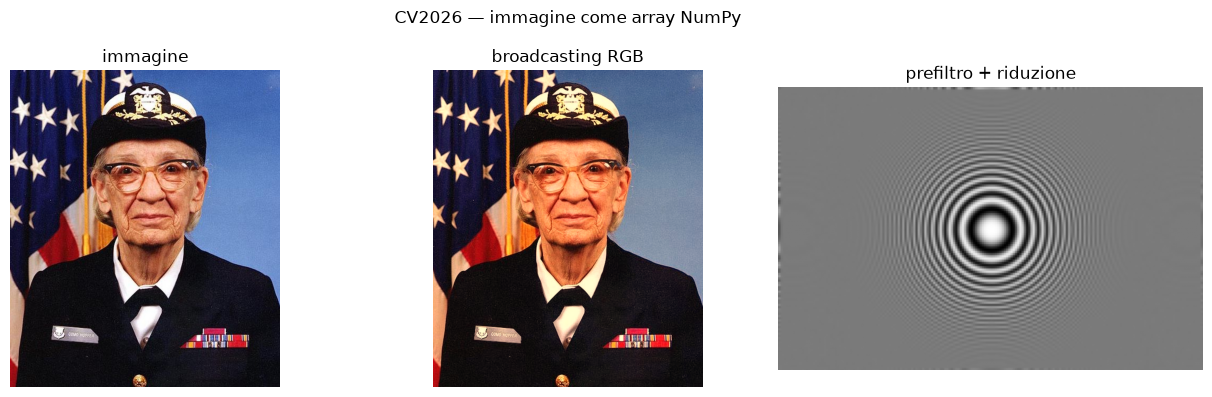

Salvato: /private/var/folders/kz/8sy42_wn3qz4bnd17_3y0yb40000gs/T/cv2026_l02_offline_gvvz64y2/cv2026_numpy_result_revisionato.png


In [12]:
# Figura da consegnare su Piazza insieme ai tre scatti controllati.
result_path = Path('cv2026_numpy_result_revisionato.png')
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img)
axes[0].set_title('immagine')
axes[1].imshow(balanced)
axes[1].set_title('broadcasting RGB')
axes[2].imshow(zone_filtered)
axes[2].set_title('prefiltro + riduzione')
for ax in axes:
    ax.axis('off')
fig.suptitle('CV2026 — immagine come array NumPy')
fig.tight_layout()
fig.savefig(result_path, dpi=150, bbox_inches='tight')
plt.show()
print('Salvato:', result_path.resolve())

## Discussione conclusiva

Rispondere in tre frasi, senza eseguire altro codice:

1. Che cosa descrivono `shape` e `dtype`, e perché entrambi sono necessari?
2. In che senso il bilanciamento del bianco è un'operazione di broadcasting ma non una nuova misura della scena?
3. Perché il sottocampionamento diretto può creare frequenze che l'immagine originale non conteneva?

Conservare la figura `cv2026_numpy_result_revisionato.png` insieme a previsione, parametro variato e interpretazione.

## Extra facoltativo — riallineamento prima del corso

Per un ripasso di 45, rileggere il notebook modificando crop, guadagni e fattore di riduzione, poi completare le sezioni su array, indicizzazione, tipi e broadcasting del tutorial CS231n. Non è necessario studiare classi Python o SciPy per eseguire il laboratorio.

Riferimenti: [NumPy User Guide](https://numpy.org/doc/stable/user/), [CS231n Python/NumPy Tutorial](https://cs231n.github.io/python-numpy-tutorial/).